In [ ]:
from pathlib import Path
import json, warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.visualization import ZScaleInterval
from scipy import ndimage
from scipy.optimize import curve_fit

warnings.filterwarnings("ignore")
DATA = Path("..")                      
RES = Path("results"); RES.mkdir(exist_ok=True)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "font.size": 11,
                     "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9})

In [2]:
with fits.open(DATA / "mosaic.fits") as hdul:
    data = hdul[0].data.astype(float)
    header = hdul[0].header
ny, nx = data.shape
SATURATION = float(header["SATURATE"])
print(f"image size: {nx} x {ny} pixels, saturation level {SATURATION:.0f} counts, "
      f"filter {header['FILTER'].strip()}, exposure {header['EXPTIME']:.0f} s")

image size: 2570 x 4611 pixels, saturation level 36000 counts, filter r SDSS 1018, exposure 720 s


In [3]:
BORDER_WIDTH = 150        # px masked along every edge
SATURATION_FRAC = 0.95    # pixel counts as saturated above 95% of SATURATE
SAT_DILATE_ITER = 2       # grow saturated regions by 2 px
BLEED_SKY_K = 1.0         # a bleed column ends when its median drops below sky + 1 sigma ...
BLEED_QUIET_ROWS = 6      # ... for 6 rows in a row
BLEED_COL_PAD = 6         # widen each bleed stripe by 6 px on both sides
GROW_BRIGHT_K = 3.0       # also mask anything > sky + 3 sigma that touches a bleed/saturated region
HALO_SAFETY = 1.3         # halo circle = 1.3 x measured radius
HALO_DR, HALO_K, HALO_R_MIN = 2, 1.0, 10
HALO_R_MAX, HALO_R_MAX_LARGE, HALO_LARGE_SAT_PX = 300, 700, 5000
UNSAT_PEAK_FRAC = 0.3     # unsaturated stars brighter than 30% of SATURATE also get a halo
yy, xx = np.mgrid[0:ny, 0:nx]

In [4]:
border = np.zeros((ny, nx), bool)
border[:BORDER_WIDTH, :] = border[-BORDER_WIDTH:, :] = True
border[:, :BORDER_WIDTH] = border[:, -BORDER_WIDTH:] = True


def gauss(x, a, mu, sigma):
    return a * np.exp(-(x - mu) ** 2 / (2 * sigma ** 2))


def fit_sky(values, lo=3300, hi=3600):
    counts, edges = np.histogram(values, bins=np.arange(lo, hi, 1))
    centres = 0.5 * (edges[:-1] + edges[1:])
    mode = centres[np.argmax(counts)]
    use = centres <= mode + 5
    p, _ = curve_fit(gauss, centres[use], counts[use], p0=[counts.max(), mode, 15])
    return float(p[1]), float(abs(p[2])), centres, counts, p


sky, sigma, _, _, _ = fit_sky(data[~border])
print(f"sky level = {sky:.1f} counts, sky noise sigma = {sigma:.1f} counts")

sky level = 3419.0 counts, sky noise sigma = 11.2 counts


In [5]:
saturated = (data >= SATURATION_FRAC * SATURATION) & ~border
saturated = ndimage.binary_dilation(saturated, iterations=SAT_DILATE_ITER)
sat_labels, n_sat = ndimage.label(saturated)
sat_slices = ndimage.find_objects(sat_labels)
print(f"{n_sat} saturated regions")


def trace_bleed(x_lo, x_hi, y_start, direction):
    """Walk up (+1) or down (-1) the columns until the column median is back to the sky."""
    y, last_bright, quiet = y_start, y_start, 0
    while 0 <= y < ny:
        if np.median(data[y, x_lo:x_hi + 1]) < sky + BLEED_SKY_K * sigma:
            quiet += 1
            if quiet >= BLEED_QUIET_ROWS:
                break
        else:
            quiet, last_bright = 0, y
        y += direction
    return last_bright


bleed = np.zeros((ny, nx), bool)
for sl in sat_slices:
    region = saturated[sl]
    col_counts = region.sum(axis=0)
    core = np.where(col_counts >= 0.5 * col_counts.max())[0] + sl[1].start
    c_lo, c_hi = int(core.min()), int(core.max())
    top = trace_bleed(c_lo, c_hi, sl[0].stop - 1, +1)
    bottom = trace_bleed(c_lo, c_hi, sl[0].start, -1)
    bleed[bottom:top + 1, max(0, c_lo - BLEED_COL_PAD):min(nx, c_hi + BLEED_COL_PAD + 1)] = True

# grow into any bright region connected to a saturated/bleed pixel
bright = data > sky + GROW_BRIGHT_K * sigma
bl, _ = ndimage.label(bright)
touching = np.unique(bl[(saturated | bleed) & bright]); touching = touching[touching != 0]
bleed |= np.isin(bl, touching)

25 saturated regions


In [6]:
halo = np.zeros((ny, nx), bool)


def halo_radius(xc, yc, r_max):
    x0, x1 = max(0, int(xc - r_max)), min(nx, int(xc + r_max) + 1)
    y0, y1 = max(0, int(yc - r_max)), min(ny, int(yc + r_max) + 1)
    cut = data[y0:y1, x0:x1]
    bad = (saturated | bleed)[y0:y1, x0:x1]
    r = np.hypot(xx[y0:y1, x0:x1] - xc, yy[y0:y1, x0:x1] - yc)
    radii, prof = [], []
    for r_in in np.arange(HALO_R_MIN, r_max, HALO_DR):
        ring = (r >= r_in) & (r < r_in + HALO_DR) & ~bad
        if ring.sum() >= 5:
            radii.append(r_in + HALO_DR); prof.append(np.median(cut[ring]))
    if not radii:
        return float(r_max)
    radii, prof = np.array(radii), np.array(prof)
    plateau = np.median(prof[radii >= 0.8 * r_max])
    below = np.where(prof < plateau + HALO_K * sigma)[0]
    return float(radii[below[0]]) if len(below) else float(r_max)


def mask_circle(xc, yc, r):
    x0, x1 = max(0, int(xc - r - 1)), min(nx, int(xc + r + 2))
    y0, y1 = max(0, int(yc - r - 1)), min(ny, int(yc + r + 2))
    halo[y0:y1, x0:x1] |= (xx[y0:y1, x0:x1] - xc) ** 2 + (yy[y0:y1, x0:x1] - yc) ** 2 <= r ** 2


stars = []
for label_id, sl in enumerate(sat_slices, start=1):          # saturated stars
    region = sat_labels[sl] == label_id
    iy = int(np.argmax(region.sum(axis=1)))
    ix = int(np.median(np.where(region[iy])[0]))
    yc, xc, npx = sl[0].start + iy, sl[1].start + ix, int(region.sum())
    r = HALO_SAFETY * halo_radius(xc, yc, HALO_R_MAX_LARGE if npx > HALO_LARGE_SAT_PX else HALO_R_MAX)
    mask_circle(xc, yc, r); stars.append((xc, yc, r))

current = border | saturated | bleed | halo                    # bright but unsaturated stars
pk_labels, _ = ndimage.label((data > UNSAT_PEAK_FRAC * SATURATION) & ~current)
for i, sl in enumerate(ndimage.find_objects(pk_labels), start=1):
    sub = np.where(pk_labels[sl] == i, data[sl], -np.inf)
    iy, ix = np.unravel_index(np.argmax(sub), sub.shape)
    yc, xc = sl[0].start + iy, sl[1].start + ix
    r = HALO_SAFETY * halo_radius(xc, yc, HALO_R_MAX)
    mask_circle(xc, yc, r); stars.append((xc, yc, r))
print(f"halos drawn around {len(stars)} bright stars")

halos drawn around 51 bright stars


In [7]:
mask = border | saturated | bleed | halo
layer_code = np.zeros((ny, nx), np.uint8)          # 1 border, 2 saturated, 3 bleed, 4 halo (first that applies)
for code, layer in ((1, border), (2, saturated), (3, bleed), (4, halo)):
    layer_code[layer & (layer_code == 0)] = code
fits.PrimaryHDU(mask.astype(np.uint8)).writeto(RES / "mask.fits", overwrite=True)
fits.PrimaryHDU(layer_code).writeto(RES / "mask_layers.fits", overwrite=True)
summary = {"sky": sky, "sigma": sigma, "masked_fraction": float(mask.mean()),
           "layers_pixels": {n: int(l.sum()) for n, l in (("border", border), ("saturated", saturated),
                                                          ("bleed", bleed), ("halo", halo))}}
json.dump(summary, open(RES / "mask_summary.json", "w"), indent=1)
print(f"masked {100 * mask.mean():.1f}% of the image "
      f"(border alone {100 * border.mean():.1f}%)")

masked 27.8% of the image (border alone 17.4%)


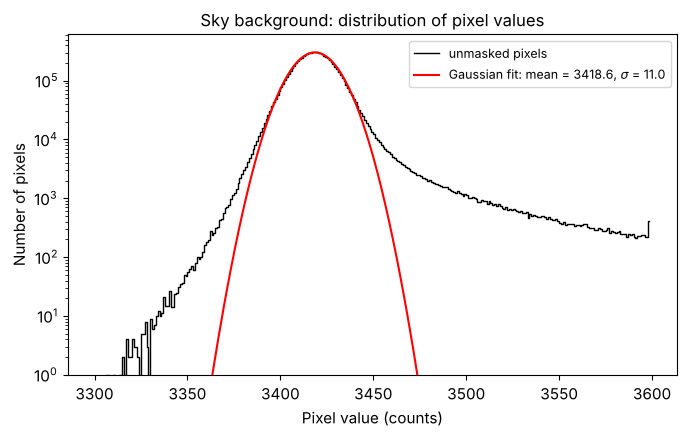

In [8]:
_, _, centres, counts, p = fit_sky(data[~mask])
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.step(centres, counts, where="mid", color="k", lw=1, label="unmasked pixels")
ax.plot(centres, gauss(centres, *p), "r", lw=1.5,
        label=fr"Gaussian fit: mean = {p[1]:.1f}, $\sigma$ = {abs(p[2]):.1f}")
ax.set_yscale("log"); ax.set_ylim(1, counts.max() * 2)
ax.set_xlabel("Pixel value (counts)"); ax.set_ylabel("Number of pixels")
ax.set_title("Sky background: distribution of pixel values")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "01_sky_histogram.png"); plt.show()

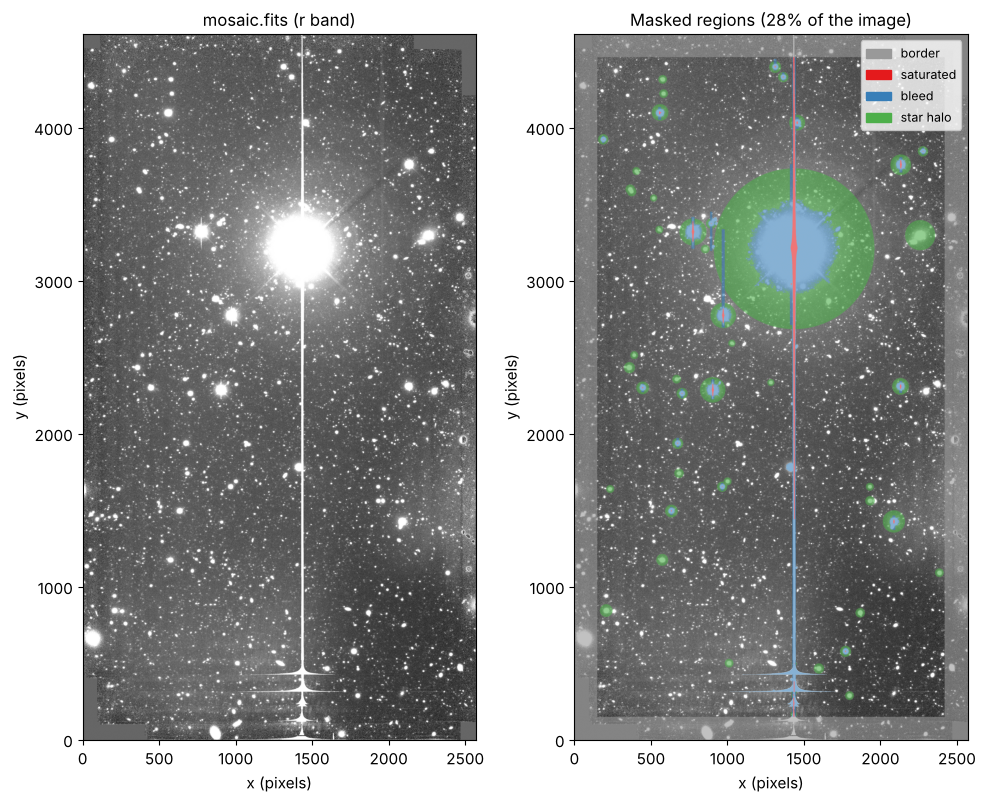

In [9]:
vmin, vmax = ZScaleInterval().get_limits(data[~mask])
fig, axes = plt.subplots(1, 2, figsize=(10, 8.5))
axes[0].imshow(data, origin="lower", cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("mosaic.fits (r band)")
axes[1].imshow(data, origin="lower", cmap="gray", vmin=vmin, vmax=vmax)
colours = ["#999999", "#e41a1c", "#377eb8", "#4daf4a"]
cmap = plt.matplotlib.colors.ListedColormap(colours)
axes[1].imshow(np.ma.masked_where(layer_code == 0, layer_code), origin="lower", cmap=cmap,
               vmin=0.5, vmax=4.5, alpha=0.6)
handles = [plt.matplotlib.patches.Patch(color=c, label=n) for c, n in zip(colours, ["border", "saturated", "bleed", "star halo"])]
axes[1].legend(handles=handles, loc="upper right")
axes[1].set_title(f"Masked regions ({100 * mask.mean():.0f}% of the image)")
for ax in axes:
    ax.set_xlabel("x (pixels)"); ax.set_ylabel("y (pixels)")
fig.tight_layout(); fig.savefig(FIG / "01_mask.png"); plt.show()